# Proyecto I – Preparación del dataset y EDA inicial
## 1. Introducción

**Problema:** en Colombia una parte importante de los ocupados no cotiza a pensión, y eso deja a muchas personas sin protección en la vejez.

**Pregunta del proyecto:** ¿qué probabilidad tiene un trabajador colombiano de cotizar a pensión, según su perfil?

**Variable objetivo:** `cotiza_pension` (P6920 en la GEIH): 1 = cotiza, 0 = no cotiza. Los ya pensionados (código 3) se excluyen.

**Para qué sirve:** fondos de pensiones, Colpensiones, UGPP y política pública. También permite medir cuántos trabajadores ganan 1 SMMLV o más y aun así no cotizan.

**Fuente:** Gran Encuesta Integrada de Hogares (GEIH) 2025, DANE, módulo de ocupados.

**Alcance de esta fase:** solo preparación de datos y EDA. El modelado (regresión logística y boosting, con entrenamiento enero–septiembre y prueba octubre–diciembre) viene después.

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carga de datos

In [ ]:
# ruta = r'C:\Users\User\Desktop\Esp_Ciencia_Datos_e_IA\Proyecto_1\repo_git\proyecto_1_esp_data_science_ia\data\geih_2025_ocupados_crudo.csv'
ruta = "data/geih_2025_ocupados_crudo.csv"
df = pd.read_csv(ruta)
df.shape

(358029, 26)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 358029 entries, 0 to 358028
Data columns (total 26 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   anio         358029 non-null  int64  
 1   mes          358029 non-null  int64  
 2   DIRECTORIO   358029 non-null  int64  
 3   SECUENCIA_P  358029 non-null  int64  
 4   ORDEN        358029 non-null  int64  
 5   HOGAR        358029 non-null  int64  
 6   MES          358029 non-null  int64  
 7   DPTO         358029 non-null  int64  
 8   CLASE        358029 non-null  int64  
 9   FEX_C18      358029 non-null  float64
 10  P6040        358029 non-null  int64  
 11  P3271        358029 non-null  int64  
 12  P6050        358029 non-null  int64  
 13  P6070        358029 non-null  float64
 14  P3042        358029 non-null  float64
 15  OCI          358029 non-null  float64
 16  P6920        358029 non-null  float64
 17  P6430        358029 non-null  float64
 18  P3069        358029 non-null  float

In [6]:
df.head()

,anio,mes,DIRECTORIO,SECUENCIA_P,ORDEN,HOGAR,MES,DPTO,CLASE,FEX_C18,...,P6920,P6430,P3069,P6880,P6800,P6426,P6440,INGLABO,RAMA2D_R4,P4030S1A1
0,2025,1,8086872,1,1,1,1,13,2,2184.752283,...,2.0,3.0,1.0,2.0,24.0,10.0,1.0,1040000.0,97.0,2.0
1,2025,1,8086874,1,2,1,1,13,2,1208.490211,...,2.0,4.0,1.0,8.0,60.0,480.0,2.0,700000.0,1.0,2.0
2,2025,1,8086874,1,3,1,1,13,2,1208.490211,...,2.0,1.0,2.0,8.0,50.0,12.0,1.0,1450000.0,1.0,2.0
3,2025,1,8086876,1,2,1,1,13,2,2420.064922,...,2.0,4.0,1.0,1.0,40.0,216.0,2.0,350000.0,47.0,2.0
4,2025,1,8086876,1,3,1,1,13,2,2420.064922,...,2.0,7.0,2.0,8.0,50.0,144.0,1.0,1350000.0,1.0,2.0


## 3. Diccionario de datos

Columna nueva, código original del DANE, descripción y si entra al modelo.

| Columna nueva | Código DANE | Descripción | ¿Entra al modelo? |
|---|---|---|---|
| anio | anio | Año de la encuesta (2025) | No (constante) |
| mes | mes / MES | Mes de la encuesta | No como variable; se usa para el split temporal |
| directorio | DIRECTORIO | Identificador de la vivienda | No (identificador) |
| secuencia_p | SECUENCIA_P | Identificador de la secuencia | No (identificador) |
| orden | ORDEN | Número de la persona en el hogar | No (identificador) |
| hogar | HOGAR | Número del hogar en la vivienda | No (identificador) |
| departamento | DPTO | Departamento | Sí |
| zona | CLASE | Cabecera (urbano) o resto (rural) | Sí |
| factor_expansion | FEX_C18 | Factor de expansión de la encuesta | No (se usa para estimar totales) |
| edad | P6040 | Edad en años | Sí |
| sexo | P3271 | Sexo | Sí |
| parentesco_jefe | P6050 | Parentesco con el jefe(a) del hogar | Sí |
| estado_civil | P6070 | Estado civil | Sí |
| nivel_educativo | P3042 | Nivel educativo más alto alcanzado | Sí |
| (se elimina) | OCI | Ocupado (siempre 1 en este archivo) | No (constante) |
| cotiza_pension | P6920 | ¿Cotiza a un fondo de pensiones? | Variable objetivo |
| posicion_ocupacional | P6430 | Posición ocupacional en el trabajo | Sí |
| tamano_empresa | P3069 | Cantidad de personas en la empresa o negocio | Sí |
| lugar_trabajo | P6880 | Lugar donde realiza el trabajo (código) | Sí |
| horas_semana | P6800 | Horas trabajadas a la semana | Sí |
| meses_en_empresa | P6426 | Meses trabajando en la empresa o negocio | Sí |
| tiene_contrato | P6440 | ¿Tiene contrato? (1 = sí, 0 = no) | Se prueba con y sin ella |
| ingreso | INGLABO | Ingreso laboral mensual (pesos) | No directo; se usa `ingreso_smmlv` |
| ingreso_smmlv | (calculada) | Ingreso dividido por el SMMLV 2025 | Sí |
| gana_1_smmlv_o_mas | (calculada) | 1 si ingreso ≥ 1 SMMLV, 0 si no | Para análisis; el modelo usa `ingreso_smmlv` |
| rama_2d | RAMA2D_R4 | Rama de actividad (CIIU Rev. 4, 2 dígitos) | Sí |
| estrato | P4030S1A1 | Estrato de la vivienda (energía eléctrica) | Sí |

**Origen del diccionario.** El archivo crudo solo trae códigos (P6800, P3042, etc.), sin descripciones, y los metadatos que vienen con los datos descargados (`metadata/2025.json`) solo describen la encuesta en general, no cada variable. Por eso los nombres y las categorías de la tabla salen del cuestionario y los diccionarios de la GEIH del DANE, tal como los conozco, y **no de un archivo incluido en el proyecto**. Para no depender solo de eso, se contrastaron con los datos:

- **Confirmadas con los datos:** `estado_civil` (edad promedio de cada código: unión libre reciente 31 años, viudo(a) 60), `posicion_ocupacional` (los familiares sin remuneración, código 6, no tienen ingreso; los empleados de empresa y del gobierno tienen contrato), `tamano_empresa` (el código 1 son casi todos cuenta propia y la cotización sube con cada código), `nivel_educativo` (la cotización sube con el nivel), `departamento`, `zona`, `sexo`, `edad`, `horas_semana` (mediana de 46 horas) e `ingreso` (el valor más repetido es 1.423.500, el SMMLV 2025).
- **Deducidas, por confirmar:** los códigos 9 y 10 de `tamano_empresa`, los códigos 7 y 8 de `posicion_ocupacional`, y el sentido de 1/2 en `tiene_contrato`.
- **Sin confirmar, por eso no se tradujeron:** `parentesco_jefe` (más allá de jefe, pareja e hijo), `lugar_trabajo` y los valores 0 y 9 de `estrato`.

Antes de entregar el proyecto conviene revisar estos puntos contra el diccionario oficial de la GEIH 2025 en la página del DANE.

## 4. Limpieza

Primero se eliminan `MES` (idéntica a `mes`, solo cambia la mayúscula) y `OCI` (todos son ocupados). Luego se pasan los nombres a minúscula con nombres claros.

In [7]:
print((df['mes'] != df['MES']).sum())
print(df['OCI'].unique())

0
[1.]


In [8]:
df = df.drop(columns=['MES', 'OCI'])
df.columns = df.columns.str.lower()

df = df.rename(columns={
    'dpto': 'departamento',
    'clase': 'zona',
    'fex_c18': 'factor_expansion',
    'p6040': 'edad',
    'p3271': 'sexo',
    'p6050': 'parentesco_jefe',
    'p6070': 'estado_civil',
    'p3042': 'nivel_educativo',
    'p6920': 'cotiza_pension',
    'p6430': 'posicion_ocupacional',
    'p3069': 'tamano_empresa',
    'p6880': 'lugar_trabajo',
    'p6800': 'horas_semana',
    'p6426': 'meses_en_empresa',
    'p6440': 'tiene_contrato',
    'inglabo': 'ingreso',
    'rama2d_r4': 'rama_2d',
    'p4030s1a1': 'estrato',
})
df.columns.tolist()

['anio',
 'mes',
 'directorio',
 'secuencia_p',
 'orden',
 'hogar',
 'departamento',
 'zona',
 'factor_expansion',
 'edad',
 'sexo',
 'parentesco_jefe',
 'estado_civil',
 'nivel_educativo',
 'cotiza_pension',
 'posicion_ocupacional',
 'tamano_empresa',
 'lugar_trabajo',
 'horas_semana',
 'meses_en_empresa',
 'tiene_contrato',
 'ingreso',
 'rama_2d',
 'estrato']

**Números.** Se verifica el tipo de las columnas numéricas. El factor de expansión ya se leyó como número con punto decimal (no tiene comas); se deja como `float`.

In [9]:
columnas_numericas = ['factor_expansion', 'ingreso', 'edad', 'horas_semana', 'meses_en_empresa']
print(df[columnas_numericas].dtypes)

df[columnas_numericas].describe()

factor_expansion    float64
ingreso             float64
edad                  int64
horas_semana        float64
meses_en_empresa    float64
dtype: object


,factor_expansion,ingreso,edad,horas_semana,meses_en_empresa
count,358029.000000,3.498300e+05,358029.000000,358029.000000,358029.000000
mean,798.620241,1.764269e+06,41.890408,43.581478,84.601178
std,1131.154344,2.232395e+06,14.180345,12.981913,111.223761
min,6.703899,0.000000e+00,15.000000,1.000000,0.000000
25%,161.529877,8.000000e+05,30.000000,40.000000,12.000000
50%,328.868619,1.423500e+06,41.000000,46.000000,36.000000
75%,961.490374,1.900000e+06,52.000000,48.000000,120.000000
max,17668.825277,1.030000e+08,100.000000,130.000000,950.000000


**Pensionados y variable objetivo.** En P6920: 1 = sí cotiza, 2 = no cotiza, 3 = ya pensionado. Se quitan los pensionados y se deja 1/0.

In [10]:
print(df['cotiza_pension'].value_counts())

df = df[df['cotiza_pension'] != 3].copy()
df['cotiza_pension'] = df['cotiza_pension'].map({1: 1, 2: 0})

df['cotiza_pension'].value_counts()

cotiza_pension
2.0    200796
1.0    150925
3.0      6308
Name: count, dtype: int64


cotiza_pension
0    200796
1    150925
Name: count, dtype: int64

**Códigos a palabras.** Se usan los códigos de la GEIH. Algunas categorías se confirmaron con los datos (por ejemplo, la edad promedio de cada estado civil y los ingresos de cada posición ocupacional). Los códigos que no se pudieron confirmar se dejaron agrupados o sin cambiar, y se avisa en las conclusiones.

In [11]:
df['sexo'] = df['sexo'].map({1: 'Hombre', 2: 'Mujer'})

df['zona'] = df['zona'].map({1: 'Urbano', 2: 'Rural'})

df['estado_civil'] = df['estado_civil'].map({
    1: 'Unión libre menos de 2 años',
    2: 'Unión libre 2 años o más',
    3: 'Casado(a)',
    4: 'Separado(a) o divorciado(a)',
    5: 'Viudo(a)',
    6: 'Soltero(a)',
})

df['nivel_educativo'] = df['nivel_educativo'].map({
    1: 'Ninguno',
    2: 'Preescolar',
    3: 'Básica primaria',
    4: 'Básica secundaria',
    5: 'Media académica',
    6: 'Media técnica',
    7: 'Normalista',
    8: 'Técnica profesional',
    9: 'Tecnológica',
    10: 'Universitaria',
    11: 'Especialización',
    12: 'Maestría',
    13: 'Doctorado',
    99: 'No sabe',
})

df['posicion_ocupacional'] = df['posicion_ocupacional'].map({
    1: 'Empleado empresa particular',
    2: 'Empleado del gobierno',
    3: 'Empleado doméstico',
    4: 'Cuenta propia',
    5: 'Patrón o empleador',
    6: 'Familiar sin remuneración',
    7: 'Jornalero o peón',
    8: 'Otro',
})

df['tamano_empresa'] = df['tamano_empresa'].map({
    1: 'Trabaja solo',
    2: '2 a 3',
    3: '4 a 5',
    4: '6 a 10',
    5: '11 a 19',
    6: '20 a 30',
    7: '31 a 50',
    8: '51 a 100',
    9: '101 a 200',
    10: '201 o más',
})

df['parentesco_jefe'] = df['parentesco_jefe'].map({
    1: 'Jefe(a) del hogar',
    2: 'Pareja del jefe(a)',
    3: 'Hijo(a)',
}).fillna('Otro')

df['tiene_contrato'] = df['tiene_contrato'].map({1: 1, 2: 0})

df['departamento'] = df['departamento'].map({
    5: 'Antioquia', 8: 'Atlántico', 11: 'Bogotá D.C.', 13: 'Bolívar', 15: 'Boyacá',
    17: 'Caldas', 18: 'Caquetá', 19: 'Cauca', 20: 'Cesar', 23: 'Córdoba',
    25: 'Cundinamarca', 27: 'Chocó', 41: 'Huila', 44: 'La Guajira', 47: 'Magdalena',
    50: 'Meta', 52: 'Nariño', 54: 'Norte de Santander', 63: 'Quindío', 66: 'Risaralda',
    68: 'Santander', 70: 'Sucre', 73: 'Tolima', 76: 'Valle del Cauca', 81: 'Arauca',
    85: 'Casanare', 86: 'Putumayo', 88: 'San Andrés', 91: 'Amazonas', 94: 'Guainía',
    95: 'Guaviare', 97: 'Vaupés', 99: 'Vichada',
})

df[['sexo', 'zona', 'estado_civil', 'nivel_educativo', 'posicion_ocupacional',
    'tamano_empresa', 'parentesco_jefe', 'tiene_contrato', 'departamento']].isna().sum()

sexo                    0
zona                    0
estado_civil            0
nivel_educativo         0
posicion_ocupacional    0
tamano_empresa          0
parentesco_jefe         0
tiene_contrato          0
departamento            0
dtype: int64

Si algún valor no estaba en el diccionario, aparecería arriba como nulo. Todos los conteos deben ser cero.

**Ingreso en SMMLV.** El salario mínimo mensual de 2025 es de $1.423.500 (también es el valor más repetido en `ingreso`). Si el ingreso es nulo, `gana_1_smmlv_o_mas` también queda nulo.

In [12]:
smmlv = 1423500

df['ingreso_smmlv'] = df['ingreso'] / smmlv
df['gana_1_smmlv_o_mas'] = (df['ingreso_smmlv'] >= 1).astype(float)
df.loc[df['ingreso'].isna(), 'gana_1_smmlv_o_mas'] = None

df[['ingreso', 'ingreso_smmlv', 'gana_1_smmlv_o_mas']].describe()

,ingreso,ingreso_smmlv,gana_1_smmlv_o_mas
count,3.438050e+05,343805.000000,343805.000000
mean,1.747716e+06,1.227760,0.516636
std,2.174840e+06,1.527812,0.499724
min,0.000000e+00,0.000000,0.000000
25%,8.000000e+05,0.561995,0.000000
50%,1.423500e+06,1.000000,1.000000
75%,1.900000e+06,1.334738,1.000000
max,1.030000e+08,72.356867,1.000000


In [13]:
print(df.shape)
df.head()

(351721, 26)


,anio,mes,directorio,secuencia_p,orden,hogar,departamento,zona,factor_expansion,edad,...,tamano_empresa,lugar_trabajo,horas_semana,meses_en_empresa,tiene_contrato,ingreso,rama_2d,estrato,ingreso_smmlv,gana_1_smmlv_o_mas
0,2025,1,8086872,1,1,1,Bolívar,Rural,2184.752283,54,...,Trabaja solo,2.0,24.0,10.0,1,1040000.0,97.0,2.0,0.730594,0.0
1,2025,1,8086874,1,2,1,Bolívar,Rural,1208.490211,60,...,Trabaja solo,8.0,60.0,480.0,0,700000.0,1.0,2.0,0.491746,0.0
2,2025,1,8086874,1,3,1,Bolívar,Rural,1208.490211,59,...,2 a 3,8.0,50.0,12.0,1,1450000.0,1.0,2.0,1.018616,1.0
3,2025,1,8086876,1,2,1,Bolívar,Rural,2420.064922,45,...,Trabaja solo,1.0,40.0,216.0,0,350000.0,47.0,2.0,0.245873,0.0
4,2025,1,8086876,1,3,1,Bolívar,Rural,2420.064922,44,...,2 a 3,8.0,50.0,144.0,1,1350000.0,1.0,2.0,0.948367,0.0


## 5. Variables excluidas por fuga de información

Hay variables de la GEIH que se contestan **solo si la persona ya cotiza**, o que son una consecuencia directa de cotizar. Si entraran al modelo, este "vería" la respuesta y las predicciones serían inútiles para el uso real. Por eso **no se usan**:

- **Fondo al que cotiza:** solo lo responde quien cotiza.
- **Quién paga el aporte:** igual, solo aplica a quien cotiza.
- **Régimen de salud contributivo:** en Colombia está atado a la relación laboral formal; quien cotiza a pensión casi siempre está en el contributivo.
- **ARL (riesgos laborales):** se afilia junto con salud y pensión.
- **Caja de compensación:** también viene con el empleo formal.
- **Informalidad del DANE:** se construye usando, entre otras cosas, si cotiza a pensión.

El archivo crudo que se recibió ya no trae estas columnas, así que no hay que quitarlas.

**`tiene_contrato`** se deja en el dataset, pero no se descarta ni se asume buena: es muy informativa y puede estar muy ligada a la formalidad. En el modelado se probará **con y sin** esta variable para ver cuánto cambia el resultado.

## 6. Variable objetivo

In [14]:
conteo = df['cotiza_pension'].value_counts()
porcentaje = df['cotiza_pension'].value_counts(normalize=True) * 100
print(conteo)
print(porcentaje.round(1))

peso = (df['cotiza_pension'] * df['factor_expansion']).sum() / df['factor_expansion'].sum() * 100
print('Con factor de expansión cotiza:', round(peso, 1), '%')

cotiza_pension
0    200796
1    150925
Name: count, dtype: int64
cotiza_pension
0    57.1
1    42.9
Name: proportion, dtype: float64
Con factor de expansión cotiza: 44.0 %


Cotiza cerca del 43 % y no cotiza cerca del 57 %. Las clases **no están muy desbalanceadas** (hay bastantes casos de ambas), así que no hace falta remuestrear; para el modelado basta con medir con métricas como AUC, no solo exactitud.

## 7. EDA básico

**Nulos por columna.**

In [15]:
nulos = df.isna().mean() * 100
nulos = nulos[nulos > 0].sort_values()
print(nulos.round(2))

estrato               0.43
ingreso               2.25
ingreso_smmlv         2.25
gana_1_smmlv_o_mas    2.25
dtype: float64


Solo `ingreso` y `estrato` tienen nulos propios (2,25 % y 0,43 %). `ingreso_smmlv` y `gana_1_smmlv_o_mas` se calculan desde `ingreso`, por eso tienen exactamente los mismos nulos. Los nulos de ingreso son sobre todo familiares sin remuneración.

**% que cotiza por mes.**

In [16]:
por_mes = df.groupby('mes')['cotiza_pension'].mean() * 100
print(por_mes.round(1))

mes
1     42.5
2     42.1
3     42.1
4     43.3
5     42.9
6     43.7
7     43.1
8     43.4
9     43.6
10    42.8
11    42.8
12    42.5
Name: cotiza_pension, dtype: float64


La tasa se mantiene bastante estable durante el año, sin saltos fuertes entre los meses de entrenamiento (1–9) y de prueba (10–12).

**% que cotiza por edad.**

In [17]:
grupo_edad = pd.cut(df['edad'], bins=[14, 24, 34, 44, 54, 64, 120],
                    labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65+'])
por_edad = df.groupby(grupo_edad, observed=True)['cotiza_pension'].mean() * 100
print(por_edad.round(1))

edad
15-24    34.8
25-34    51.8
35-44    50.5
45-54    44.0
55-64    33.1
65+      10.2
Name: cotiza_pension, dtype: float64


La cotización sube hasta cerca de 52 % entre los 25 y 34 años, se mantiene en 50 % hasta los 44 y luego baja: 44 % a los 45–54, 33 % a los 55–64 y solo 10 % después de los 65.

**% que cotiza por sexo.**

In [18]:
por_sexo = df.groupby('sexo')['cotiza_pension'].mean() * 100
print(por_sexo.round(1))

sexo
Hombre    41.2
Mujer     45.1
Name: cotiza_pension, dtype: float64


Las mujeres cotizan un poco más que los hombres (45 % frente a 41 %), una diferencia pequeña comparada con la de otras variables.

**Cantidad de personas por nivel educativo**

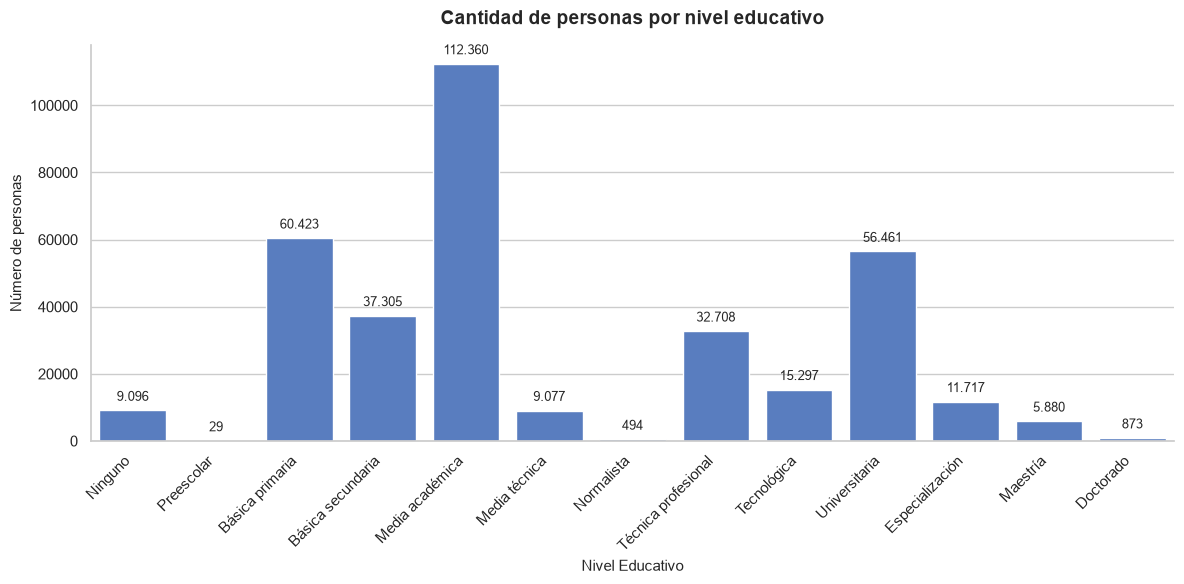

In [43]:
orden_edu = [ 'Ninguno', 'Preescolar', 'Básica primaria', 'Básica secundaria', 'Media académica', 'Media técnica', 'Normalista', 'Técnica profesional',
    'Tecnológica', 'Universitaria', 'Especialización', 'Maestría', 'Doctorado', 
]

por_edu = df.groupby('nivel_educativo')['cotiza_pension'].count()
por_edu = por_edu.reindex(orden_edu).dropna()

sns.set_theme(style='whitegrid', palette='muted')

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=por_edu.index, y=por_edu.values)

for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:,.0f}'.replace(',', '.'),
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=9,
    )

plt.title(
    'Cantidad de personas por nivel educativo',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Nivel Educativo', fontsize=11)
plt.ylabel('Número de personas', fontsize=11)
plt.xticks(rotation=45, ha='right')
sns.despine()
plt.tight_layout()
plt.show()

**% que cotiza por nivel educativo.**

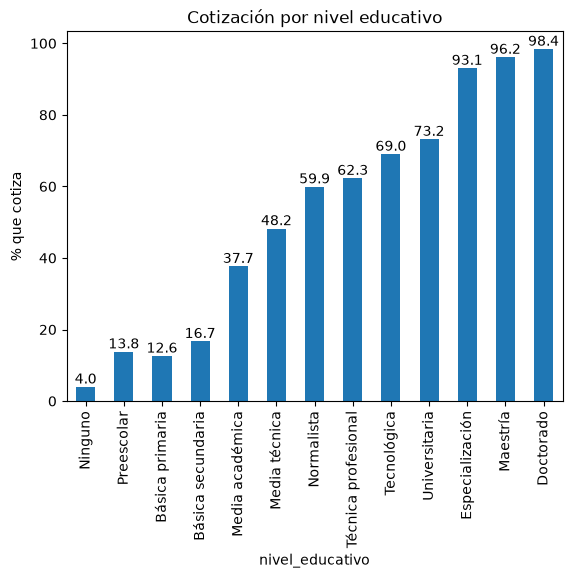

In [20]:
orden_edu = ['Ninguno', 'Preescolar', 'Básica primaria', 'Básica secundaria', 'Media académica',
             'Media técnica', 'Normalista', 'Técnica profesional', 'Tecnológica',
             'Universitaria', 'Especialización', 'Maestría', 'Doctorado']
por_edu = df.groupby('nivel_educativo')['cotiza_pension'].mean() * 100
por_edu = por_edu.reindex(orden_edu).dropna()
ax = por_edu.plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.ylabel('% que cotiza')
plt.title('Cotización por nivel educativo')
plt.xticks(rotation=90)
plt.show()

A mayor nivel educativo, mayor cotización: de 4 % sin estudios y 13 % con primaria a más de 93 % con posgrado.

**Calidad del empleo de quienes NO cotizan, por nivel educativo.** Este archivo solo trae personas ocupadas, así que no se puede comparar "con empleo" frente a "sin empleo". Aquí se mira solo a los que no cotizan y, como aproximación a la calidad de su empleo, qué parte tiene contrato y qué parte gana 1 SMMLV o más, según su nivel educativo.

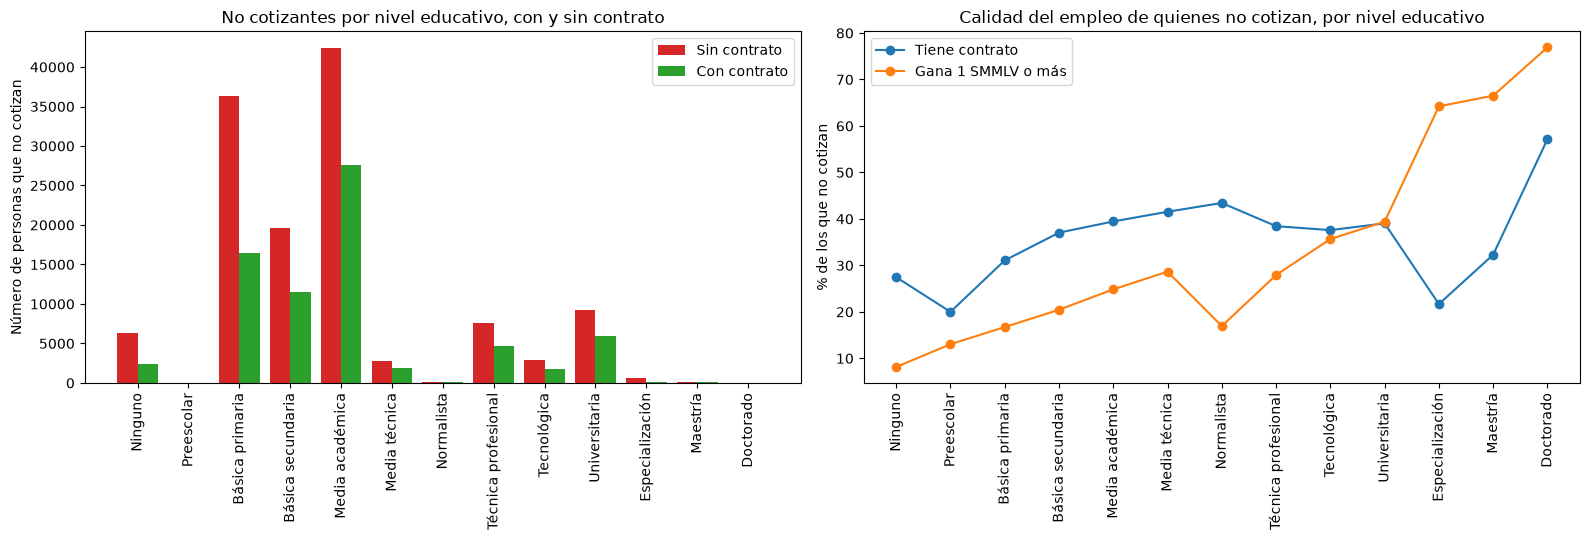

In [21]:
import numpy as np

# Solo quienes NO cotizan a pensión
d = df[(df['cotiza_pension'] == 0) & (df['nivel_educativo'].isin(orden_edu))].copy()
niveles = [n for n in orden_edu if n in d['nivel_educativo'].unique()]
x = np.arange(len(niveles))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Izquierda: cuántos no cotizantes hay por nivel educativo, con y sin contrato (barras lado a lado)
ax = axes[0]
conteo = d.groupby(['nivel_educativo', 'tiene_contrato']).size().unstack(fill_value=0).reindex(niveles)
ancho = 0.4
ax.bar(x - ancho/2, conteo[0], ancho, label='Sin contrato', color='tab:red')
ax.bar(x + ancho/2, conteo[1], ancho, label='Con contrato', color='tab:green')
ax.set_xticks(x)
ax.set_xticklabels(niveles, rotation=90)
ax.set_ylabel('Número de personas que no cotizan')
ax.set_title('No cotizantes por nivel educativo, con y sin contrato')
ax.legend()

# Derecha: calidad del empleo de los que no cotizan
ax = axes[1]
ax.plot(x, d.groupby('nivel_educativo')['tiene_contrato'].mean().reindex(niveles) * 100,
        marker='o', label='Tiene contrato')
ax.plot(x, d.groupby('nivel_educativo')['gana_1_smmlv_o_mas'].mean().reindex(niveles) * 100,
        marker='o', label='Gana 1 SMMLV o más')
ax.set_xticks(x)
ax.set_xticklabels(niveles, rotation=90)
ax.set_ylabel('% de los que no cotizan')
ax.set_title('Calidad del empleo de quienes no cotizan, por nivel educativo')
ax.legend()

plt.tight_layout()
plt.show()


Hay 200.796 ocupados que no cotizan. La mayoría tiene estudios bajos o medios: media académica (70.026), básica primaria (52.799) y básica secundaria (31.070) concentran cerca de tres cuartas partes del grupo. El contrato **no sube con la educación**: entre los que no cotizan, solo entre 28 % y 43 % tiene contrato en casi todos los niveles (36 % en total), así que tener contrato no garantiza cotizar. En cambio, el porcentaje que gana 1 SMMLV o más sí crece con el estudio, de 8 % sin estudios a 64–77 % en posgrado. Los posgrados casi no aparecen en este grupo (812 en especialización, 226 en maestría y 14 en doctorado), así que sus porcentajes se apoyan en pocos casos.

**Revisión por nivel educativo (todos los ocupados).** Para cada nivel educativo se mira la distribución del ingreso (histograma, separando quienes cotizan de quienes no) y una tabla resumen con las demás variables: cotiza, contrato, ingreso, zona, sexo y edad. En los histogramas solo se muestra el ingreso hasta 5 SMMLV para que se lean bien.

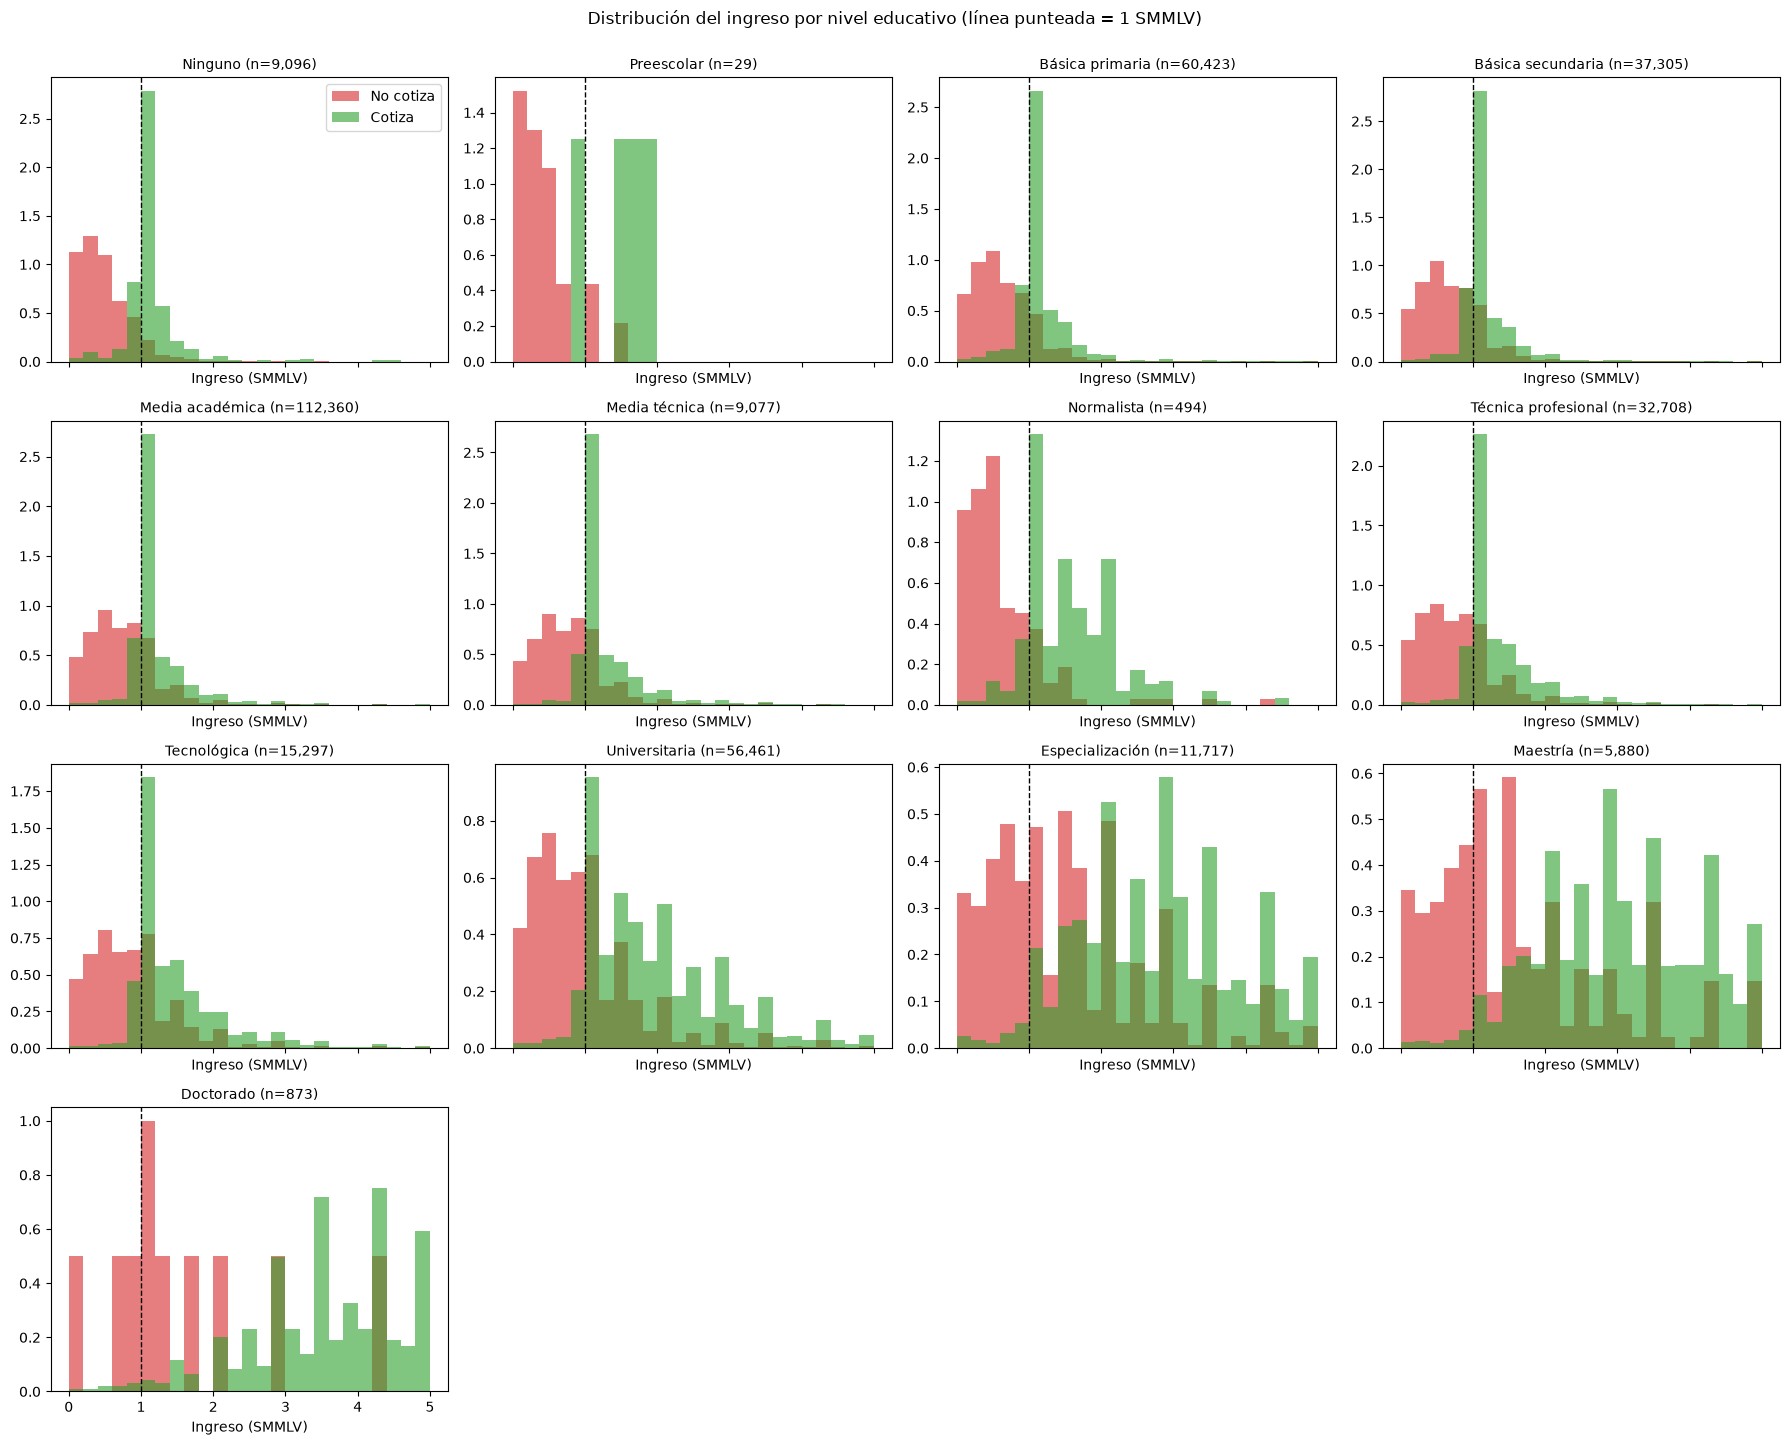

,n,cotiza,contrato,gana_1_smmlv,mediana_ingreso_smmlv,urbano,mujer,edad_media
nivel_educativo,,,,,,,,
Ninguno,9096,4.0,30.2,11.0,0.42,57.6,32.2,56.6
Preescolar,29,13.8,31.0,22.2,0.42,75.9,31.0,52.1
Básica primaria,60423,12.6,38.3,24.8,0.63,72.1,34.6,51.9
Básica secundaria,37305,16.7,46.0,30.7,0.70,83.8,36.6,42.2
Media académica,112360,37.7,59.8,47.4,0.98,90.1,42.4,38.7
Media técnica,9077,48.2,67.3,57.6,1.00,91.5,42.5,36.0
Normalista,494,59.9,76.7,60.9,1.00,88.1,75.3,40.9
Técnica profesional,32708,62.3,73.9,65.5,1.00,94.8,58.2,37.4
Tecnológica,15297,69.0,76.5,72.8,1.12,96.0,49.8,37.1


In [22]:
import numpy as np

todos = df[df['nivel_educativo'].isin(orden_edu)].copy()
niveles_t = [n for n in orden_edu if n in todos['nivel_educativo'].unique()]

# Histogramas del ingreso (en SMMLV) por nivel educativo, cotiza vs no cotiza
filas = int(np.ceil(len(niveles_t) / 4))
fig, axes = plt.subplots(filas, 4, figsize=(18, 3.6 * filas), sharex=True)
axes = axes.ravel()
bins = np.linspace(0, 5, 26)

for ax, nivel in zip(axes, niveles_t):
    sub = todos[todos['nivel_educativo'] == nivel]
    ing_no = sub.loc[sub['cotiza_pension'] == 0, 'ingreso_smmlv'].dropna()
    ing_si = sub.loc[sub['cotiza_pension'] == 1, 'ingreso_smmlv'].dropna()
    ax.hist(ing_no, bins=bins, density=True, alpha=0.6, color='tab:red', label='No cotiza')
    ax.hist(ing_si, bins=bins, density=True, alpha=0.6, color='tab:green', label='Cotiza')
    ax.axvline(1, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'{nivel} (n={len(sub):,})', fontsize=10)
    ax.set_xlabel('Ingreso (SMMLV)')

for ax in axes[len(niveles_t):]:
    ax.axis('off')
axes[0].legend()
fig.suptitle('Distribución del ingreso por nivel educativo (línea punteada = 1 SMMLV)', y=1.0)
plt.tight_layout()
plt.show()

# Tabla resumen por nivel educativo
resumen = todos.groupby('nivel_educativo').agg(
    n=('cotiza_pension', 'size'),
    cotiza=('cotiza_pension', 'mean'),
    contrato=('tiene_contrato', 'mean'),
    gana_1_smmlv=('gana_1_smmlv_o_mas', 'mean'),
    mediana_ingreso_smmlv=('ingreso_smmlv', 'median'),
    urbano=('zona', lambda s: (s == 'Urbano').mean()),
    mujer=('sexo', lambda s: (s == 'Mujer').mean()),
    edad_media=('edad', 'mean'),
).reindex(niveles_t)
for c in ['cotiza', 'contrato', 'gana_1_smmlv', 'urbano', 'mujer']:
    resumen[c] = (resumen[c] * 100).round(1)
resumen['mediana_ingreso_smmlv'] = resumen['mediana_ingreso_smmlv'].round(2)
resumen['edad_media'] = resumen['edad_media'].round(1)
resumen

El ingreso sube con la educación y separa a quienes cotizan de quienes no. La mediana de ingreso pasa de 0,42 SMMLV sin estudios a 1,48 en universitaria y 4,78 en doctorado. En todos los niveles la mediana de quienes cotizan es mayor que la de quienes no: por ejemplo, 1,83 frente a 0,84 SMMLV en universitaria y 1,00 frente a 0,56 en básica primaria. La cotización pasa de 4 % sin estudios a 73 % en universitaria y 98 % en doctorado.

Las otras variables acompañan ese patrón: la zona urbana pasa de 58 % a cerca de 97 % y el contrato de 30 % a 95 %. Las mujeres son minoría en los niveles bajos (31–42 % hasta media técnica) y mayoría en técnica profesional (58 %) y especialización (57 %). La edad media es más alta en los extremos (57 años sin estudios, 47 en doctorado) y ronda los 36–38 años entre media técnica y universitaria. Preescolar (29 personas), normalista (494) y doctorado (873) tienen pocos casos, así que sus porcentajes son menos estables.

**% que cotiza por posición ocupacional.**

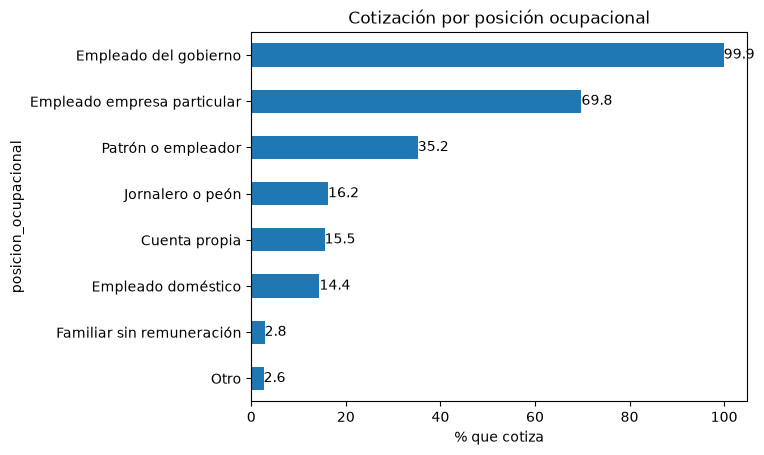

In [23]:
por_pos = df.groupby('posicion_ocupacional')['cotiza_pension'].mean() * 100
ax = por_pos.sort_values().plot(kind='barh')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.xlabel('% que cotiza')
plt.title('Cotización por posición ocupacional')
plt.show()

Casi todos los empleados del gobierno cotizan (más de 99 %) y 70 % de los de empresa particular; los patrones cotizan 35 % y cuenta propia, jornaleros, domésticos y familiares sin remuneración, menos de 17 %.

**% que cotiza por tamaño de empresa.**

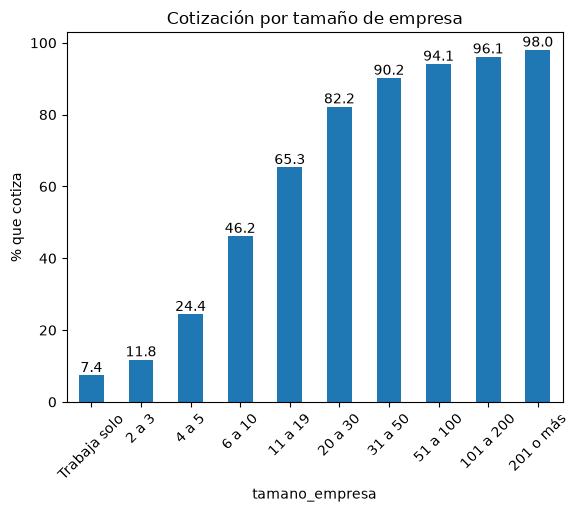

In [24]:
orden_tam = ['Trabaja solo', '2 a 3', '4 a 5', '6 a 10', '11 a 19', '20 a 30',
             '31 a 50', '51 a 100', '101 a 200', '201 o más']
por_tam = df.groupby('tamano_empresa')['cotiza_pension'].mean() * 100
por_tam = por_tam.reindex(orden_tam)
ax = por_tam.plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.ylabel('% que cotiza')
plt.title('Cotización por tamaño de empresa')
plt.xticks(rotation=45)
plt.show()

La cotización crece de forma casi continua con el tamaño: 7 % entre quienes trabajan solos, 46 % en empresas de 6 a 10 personas y más de 90 % en empresas de 31 personas o más.

**% que cotiza por zona.**

In [25]:
por_zona = df.groupby('zona')['cotiza_pension'].mean() * 100
print(por_zona.round(1))

zona
Rural     18.5
Urbano    46.3
Name: cotiza_pension, dtype: float64


En la zona urbana cotiza 46 % y en la rural solo 18 %.

**Frecuencia absoluta y relativa por sexo, según cotice o no.** Para esta sección y las siguientes, la frecuencia absoluta es el número de personas y la relativa es el porcentaje dentro de cada grupo (cada barra de la derecha suma 100 % entre "No cotiza" y "Cotiza"). La tabla agrega también el porcentaje sobre el total de ocupados. Son tablas y gráficos nuevos; el dataset no se modifica.

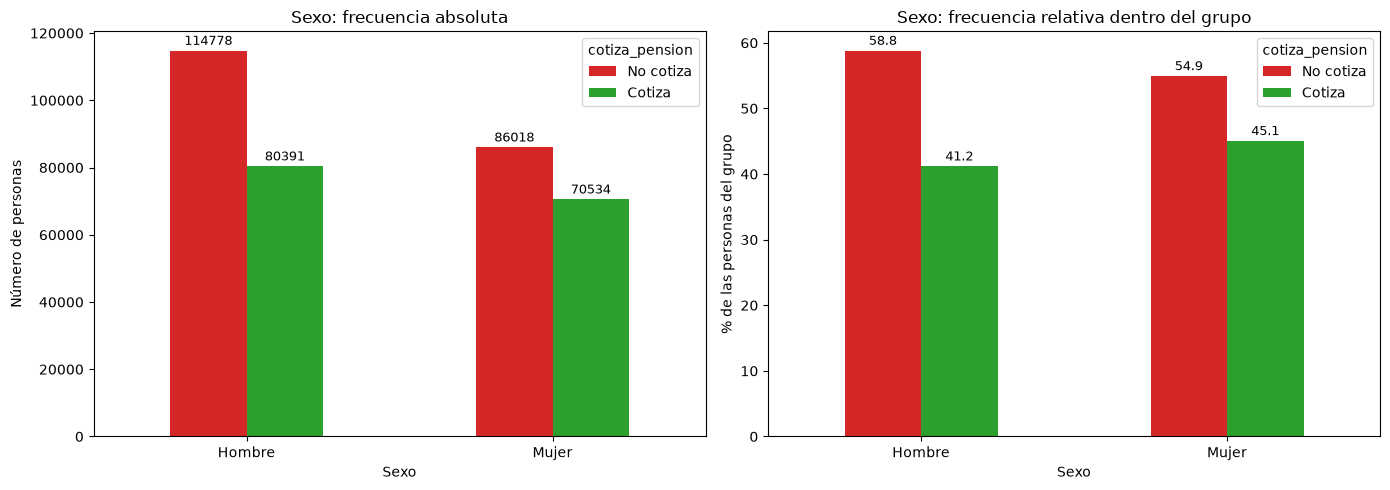

Frecuencia absoluta                % dentro del grupo         \
cotiza_pension           No cotiza Cotiza   Total          No cotiza Cotiza   
sexo                                                                          
Hombre                      114778  80391  195169               58.8   41.2   
Mujer                        86018  70534  156552               54.9   45.1   

               % del total         
cotiza_pension   No cotiza Cotiza  
sexo                               
Hombre                32.6   22.9  
Mujer                 24.5   20.1

In [26]:
etiquetas = {0: 'No cotiza', 1: 'Cotiza'}
colores = ['tab:red', 'tab:green']


def tabla_frecuencias(grupo):
    """Frecuencia absoluta y relativa de cotiza / no cotiza para cada categoría de `grupo`."""
    absoluta = pd.crosstab(grupo, df['cotiza_pension']).rename(columns=etiquetas)
    absoluta['Total'] = absoluta.sum(axis=1)
    dentro = (pd.crosstab(grupo, df['cotiza_pension'], normalize='index') * 100).round(1).rename(columns=etiquetas)
    del_total = (absoluta[['No cotiza', 'Cotiza']] / absoluta['Total'].sum() * 100).round(1)
    return pd.concat({'Frecuencia absoluta': absoluta,
                      '% dentro del grupo': dentro,
                      '% del total': del_total}, axis=1)


def graficar_frecuencias(grupo, titulo, ancho=14, rotacion=0, tam_etiqueta=9, rot_etiqueta=0):
    """Barras de frecuencia absoluta (izquierda) y relativa dentro del grupo (derecha)."""
    absoluta = pd.crosstab(grupo, df['cotiza_pension']).rename(columns=etiquetas)
    relativa = (pd.crosstab(grupo, df['cotiza_pension'], normalize='index') * 100).rename(columns=etiquetas)
    fig, axes = plt.subplots(1, 2, figsize=(ancho, 5))
    absoluta.plot(kind='bar', ax=axes[0], color=colores)
    relativa.plot(kind='bar', ax=axes[1], color=colores)
    for ax, fmt in zip(axes, ['%d', '%.1f']):
        for cont in ax.containers:
            ax.bar_label(cont, fmt=fmt, fontsize=tam_etiqueta, rotation=rot_etiqueta, padding=2)
        ax.tick_params(axis='x', rotation=rotacion)
        ax.set_xlabel(titulo)
    axes[0].set_ylabel('Número de personas')
    axes[0].set_title(f'{titulo}: frecuencia absoluta')
    axes[1].set_ylabel('% de las personas del grupo')
    axes[1].set_title(f'{titulo}: frecuencia relativa dentro del grupo')
    plt.tight_layout()
    plt.show()


graficar_frecuencias(df['sexo'], 'Sexo')
tabla_frecuencias(df['sexo'])

Hay más hombres que mujeres ocupados (195.169 frente a 156.552, es decir 55,5 % y 44,5 %), y por eso también hay más hombres entre los que no cotizan (114.778 frente a 86.018). En términos relativos, no cotiza 58,8 % de los hombres y 54,9 % de las mujeres: la diferencia es de unos 4 puntos y la cotización de las mujeres es algo mayor (45,1 % frente a 41,2 %). Con estos datos el sexo separa poco a quienes cotizan de quienes no.

**Revisión por sexo e ingreso (todos los ocupados).** Igual que con el nivel educativo: la distribución del ingreso en SMMLV (histograma, separando quienes cotizan de quienes no) y una tabla resumen con cotiza, contrato, porcentaje que gana 1 SMMLV o más y mediana de ingreso, en total y según cotice o no. Los histogramas no cortan el ingreso: solo muestran el rango de 0 a 5 SMMLV.

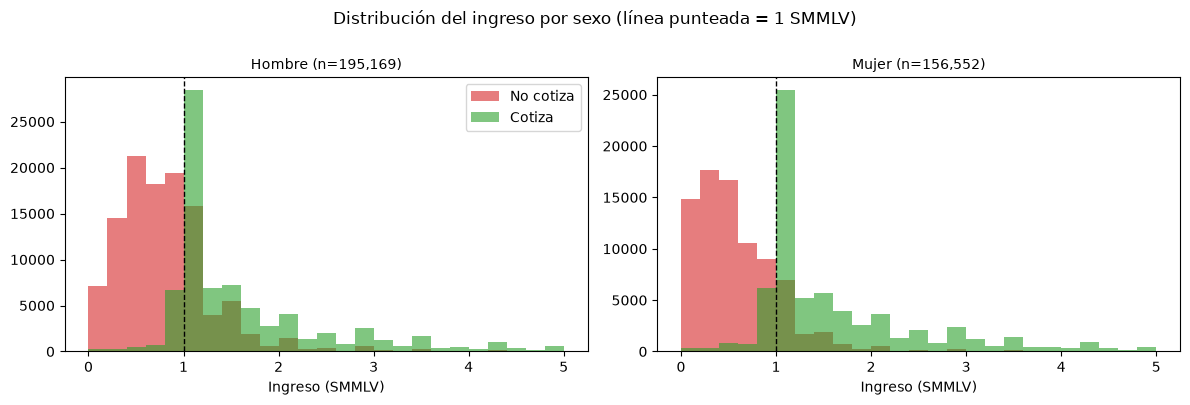

,n,cotiza,contrato,gana_1_smmlv,mediana_ingreso_smmlv,mediana_no_cotiza,mediana_cotiza
sexo,,,,,,,
Hombre,195169,41.2,57.1,53.6,1.0,0.70,1.26
Mujer,156552,45.1,64.4,49.2,1.0,0.49,1.26


In [27]:
import numpy as np


def histogramas_ingreso(grupo, titulo, columnas=3):
    """Un histograma del ingreso (en SMMLV) por categoría de `grupo`, separando cotiza / no cotiza."""
    categorias = list(grupo.cat.categories) if hasattr(grupo, 'cat') else sorted(grupo.dropna().unique())
    filas = int(np.ceil(len(categorias) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(6 * columnas, 4 * filas), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    bins = np.linspace(0, 5, 26)
    for ax, cat in zip(axes, categorias):
        sub = df[grupo == cat]
        ing_no = sub.loc[sub['cotiza_pension'] == 0, 'ingreso_smmlv'].dropna()
        ing_si = sub.loc[sub['cotiza_pension'] == 1, 'ingreso_smmlv'].dropna()
        ax.hist(ing_no, bins=bins, alpha=0.6, color='tab:red', label='No cotiza')
        ax.hist(ing_si, bins=bins, alpha=0.6, color='tab:green', label='Cotiza')
        ax.axvline(1, color='black', linestyle='--', linewidth=1)
        ax.set_title(f'{cat} (n={len(sub):,})', fontsize=10)
        ax.set_xlabel('Ingreso (SMMLV)')
    for ax in axes[len(categorias):]:
        ax.axis('off')
    axes[0].legend()
    fig.suptitle(f'Distribución del ingreso por {titulo} (línea punteada = 1 SMMLV)', y=1.0)
    plt.tight_layout()
    plt.show()


def resumen_ingreso(grupo):
    """Tabla resumen por categoría de `grupo`: cotiza, contrato e ingreso (mediana total y según cotice)."""
    res = df.groupby(grupo, observed=True).agg(
        n=('cotiza_pension', 'size'),
        cotiza=('cotiza_pension', 'mean'),
        contrato=('tiene_contrato', 'mean'),
        gana_1_smmlv=('gana_1_smmlv_o_mas', 'mean'),
        mediana_ingreso_smmlv=('ingreso_smmlv', 'median'),
    )
    med = (df.groupby([grupo, 'cotiza_pension'], observed=True)['ingreso_smmlv'].median()
             .unstack().rename(columns={0: 'mediana_no_cotiza', 1: 'mediana_cotiza'}))
    res = res.join(med)
    for c in ['cotiza', 'contrato', 'gana_1_smmlv']:
        res[c] = (res[c] * 100).round(1)
    for c in ['mediana_ingreso_smmlv', 'mediana_no_cotiza', 'mediana_cotiza']:
        res[c] = res[c].round(2)
    return res


histogramas_ingreso(df['sexo'], 'sexo', columnas=2)
resumen_ingreso(df['sexo'])

La mediana de ingreso total es igual para hombres y mujeres (1,0 SMMLV), pero los hombres ganan 1 SMMLV o más con más frecuencia (53,6 % frente a 49,2 %), aunque las mujeres tienen contrato más a menudo (64,4 % frente a 57,1 %). La diferencia grande está entre quienes cotizan y quienes no: los cotizantes tienen una mediana de 1,26 SMMLV en ambos sexos, mientras que entre los que no cotizan es de 0,70 en los hombres y solo 0,49 en las mujeres. Es decir, la mujer que no cotiza es la que tiene el ingreso más bajo. En los histogramas, los no cotizantes se concentran por debajo de 1 SMMLV y los cotizantes se desplazan hacia la derecha. Los ingresos mayores a 5 SMMLV (1,7 % de los ocupados) quedan fuera del rango graficado.

**Frecuencia absoluta y relativa por rango de edad, según cotice o no.**

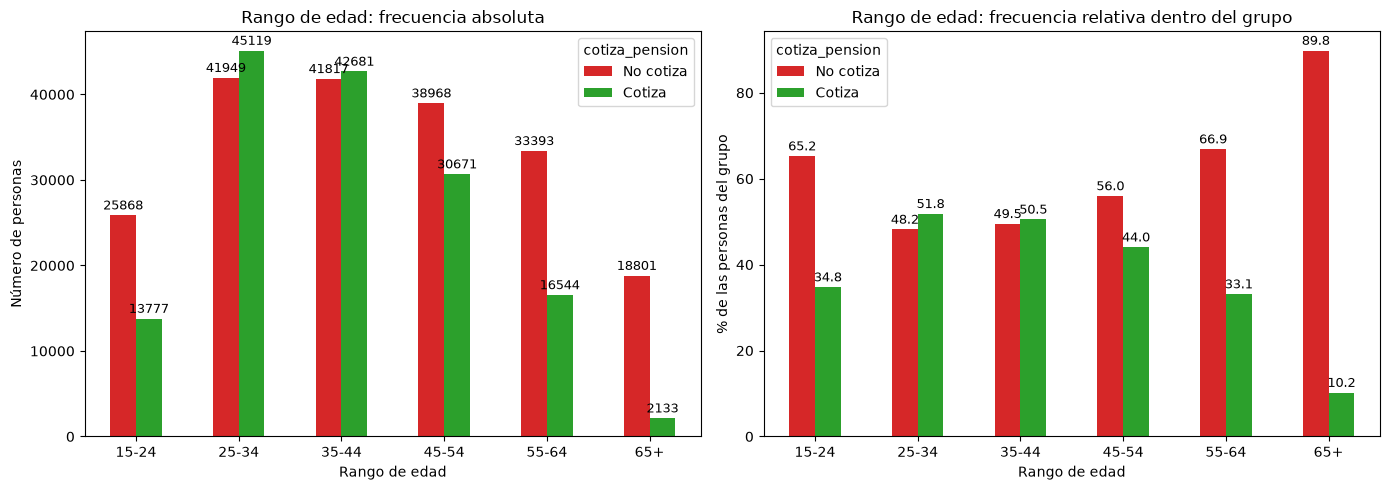

Frecuencia absoluta               % dentro del grupo         \
cotiza_pension           No cotiza Cotiza  Total          No cotiza Cotiza   
edad                                                                         
15-24                        25868  13777  39645               65.2   34.8   
25-34                        41949  45119  87068               48.2   51.8   
35-44                        41817  42681  84498               49.5   50.5   
45-54                        38968  30671  69639               56.0   44.0   
55-64                        33393  16544  49937               66.9   33.1   
65+                          18801   2133  20934               89.8   10.2   

               % del total         
cotiza_pension   No cotiza Cotiza  
edad                               
15-24                  7.4    3.9  
25-34                 11.9   12.8  
35-44                 11.9   12.1  
45-54                 11.1    8.7  
55-64                  9.5    4.7  
65+                    5.3    0.6

In [28]:
rango_edad = pd.cut(df['edad'], bins=[14, 24, 34, 44, 54, 64, 120],
                    labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65+'])

graficar_frecuencias(rango_edad, 'Rango de edad')
tabla_frecuencias(rango_edad)

Los rangos de 25–34 (87.068 personas) y 35–44 años (84.498) son los más grandes y los únicos donde cotizan más de la mitad (52 % y 51 %). Los jóvenes de 15–24 años son 39.645 ocupados y solo 35 % cotiza. Desde los 45 años el porcentaje de no cotizantes sube cada vez más: 56 % en 45–54, 67 % en 55–64 y 90 % en 65 o más, donde de 20.934 ocupados solo 2.133 cotizan. En número absoluto, el mayor grupo de no cotizantes está entre 25 y 44 años (cerca de 42.000 en cada rango), aunque ahí no son mayoría; los de 55 años o más suman 52.194, algo más de la cuarta parte de los no cotizantes, y en su caso sí son la gran mayoría de su grupo.

**Revisión por rango de edad e ingreso (todos los ocupados).** Misma estructura que en sexo: histogramas del ingreso en SMMLV separando cotiza y no cotiza, y tabla resumen con cotiza, contrato, porcentaje que gana 1 SMMLV o más y mediana de ingreso en total y según cotice o no.

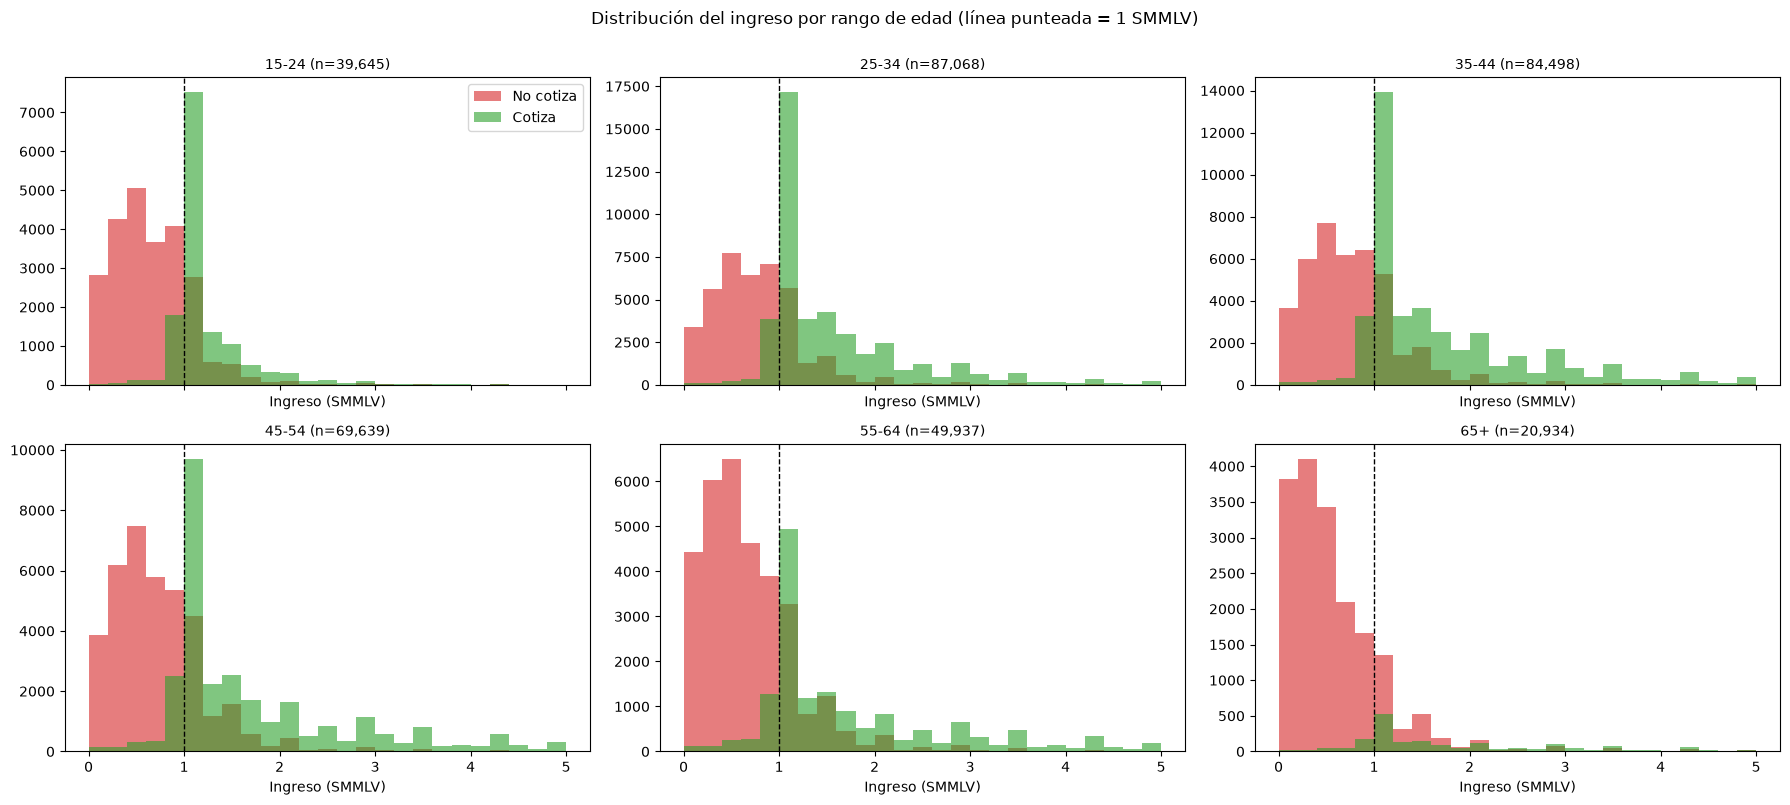

,n,cotiza,contrato,gana_1_smmlv,mediana_ingreso_smmlv,mediana_no_cotiza,mediana_cotiza
edad,,,,,,,
15-24,39645,34.8,70.9,42.1,0.91,0.60,1.00
25-34,87068,51.8,70.6,59.3,1.00,0.70,1.26
35-44,84498,50.5,64.7,58.9,1.00,0.70,1.35
45-54,69639,44.0,56.6,52.8,1.00,0.63,1.33
55-64,49937,33.1,45.9,43.4,0.84,0.56,1.36
65+,20934,10.2,27.5,23.6,0.53,0.42,1.40


In [29]:
histogramas_ingreso(rango_edad, 'rango de edad', columnas=3)
resumen_ingreso(rango_edad)

El ingreso sigue la misma forma de montaña que la cotización. El porcentaje que gana 1 SMMLV o más es de 42 % a los 15–24 años, sube a 59 % entre los 25 y 44, y baja a 53 % en 45–54, 43 % en 55–64 y 24 % desde los 65; la mediana de ingreso cae de 1,0 SMMLV a 0,84 en 55–64 y 0,53 en los de 65 o más. El contrato baja de forma más continua, de 71 % en los jóvenes a 27 % en los de 65 o más. Entre quienes no cotizan la mediana va de 0,60–0,70 SMMLV hasta los 44 años a 0,42 en los de 65 o más, mientras que la de los cotizantes sube de 1,0 en los jóvenes a 1,4 en los de 65 o más. La brecha de ingreso entre cotizar y no cotizar se ensancha con la edad. Los ingresos mayores a 5 SMMLV quedan fuera del rango graficado.

**Sexo y rango de edad combinados, según cotice o no.** Se compara dentro de cada sexo cómo cambia la cotización con la edad.

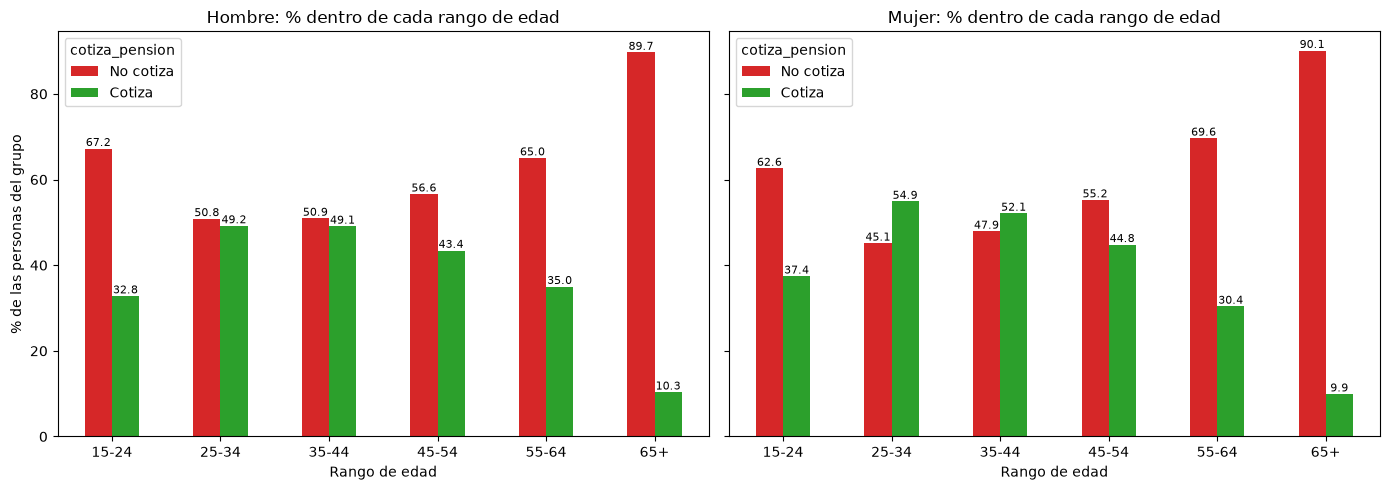

Frecuencia absoluta               % dentro del grupo         \
cotiza_pension           No cotiza Cotiza  Total          No cotiza Cotiza   
sexo   edad                                                                  
Hombre 15-24                 15329   7478  22807               67.2   32.8   
       25-34                 23716  22939  46655               50.8   49.2   
       35-44                 22567  21747  44314               50.9   49.1   
       45-54                 21306  16350  37656               56.6   43.4   
       55-64                 19403  10441  29844               65.0   35.0   
       65+                   12457   1436  13893               89.7   10.3   
Mujer  15-24                 10539   6299  16838               62.6   37.4   
       25-34                 18233  22180  40413               45.1   54.9   
       35-44                 19250  20934  40184               47.9   52.1   
       45-54                 17662  14321  31983               55.2   44.8   
       55-64                 13990   6103  20093               69.6   30.4   
       65+                    6344    697   7041               90.1    9.9   

               % del total         
cotiza_pension   No cotiza Cotiza  
sexo   edad                        
Hombre 15-24           4.4    2.1  
       25-34           6.7    6.5  
       35-44           6.4    6.2  
       45-54           6.1    4.6  
       55-64           5.5    3.0  
       65+             3.5    0.4  
Mujer  15-24           3.0    1.8  
       25-34           5.2    6.3  
       35-44           5.5    6.0  
       45-54           5.0    4.1  
       55-64           4.0    1.7  
       65+             1.8    0.2

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, sexo in zip(axes, ['Hombre', 'Mujer']):
    sub = df[df['sexo'] == sexo]
    rel = (pd.crosstab(rango_edad.loc[sub.index], sub['cotiza_pension'], normalize='index') * 100).rename(columns=etiquetas)
    rel.plot(kind='bar', ax=ax, color=colores)
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.1f', fontsize=8)
    ax.set_title(f'{sexo}: % dentro de cada rango de edad')
    ax.set_xlabel('Rango de edad')
    ax.tick_params(axis='x', rotation=0)
axes[0].set_ylabel('% de las personas del grupo')
plt.tight_layout()
plt.show()

tabla_frecuencias([df['sexo'], rango_edad])

Hasta los 54 años las mujeres cotizan más que los hombres en todos los rangos: 37 % frente a 33 % en 15–24, 55 % frente a 49 % en 25–34, 52 % frente a 49 % en 35–44 y 45 % frente a 43 % en 45–54. La relación se invierte en 55–64 años (30 % de las mujeres frente a 35 % de los hombres) y desaparece desde los 65 (10 % en ambos). Es decir, la ventaja de las mujeres se concentra en las edades de mayor actividad laboral y se pierde cerca de la edad de pensión. En ambos sexos el patrón por edad es el mismo: máximo entre 25 y 44 años y caída fuerte después de los 54.

**Frecuencia absoluta y relativa por nivel educativo, según cotice o no.**

C:\Users\julian.urrea\AppData\Local\Temp\ipykernel_52160\3756075673.py:1: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  nivel_ord = pd.Series(pd.Categorical(df['nivel_educativo'], categories=orden_edu, ordered=True),


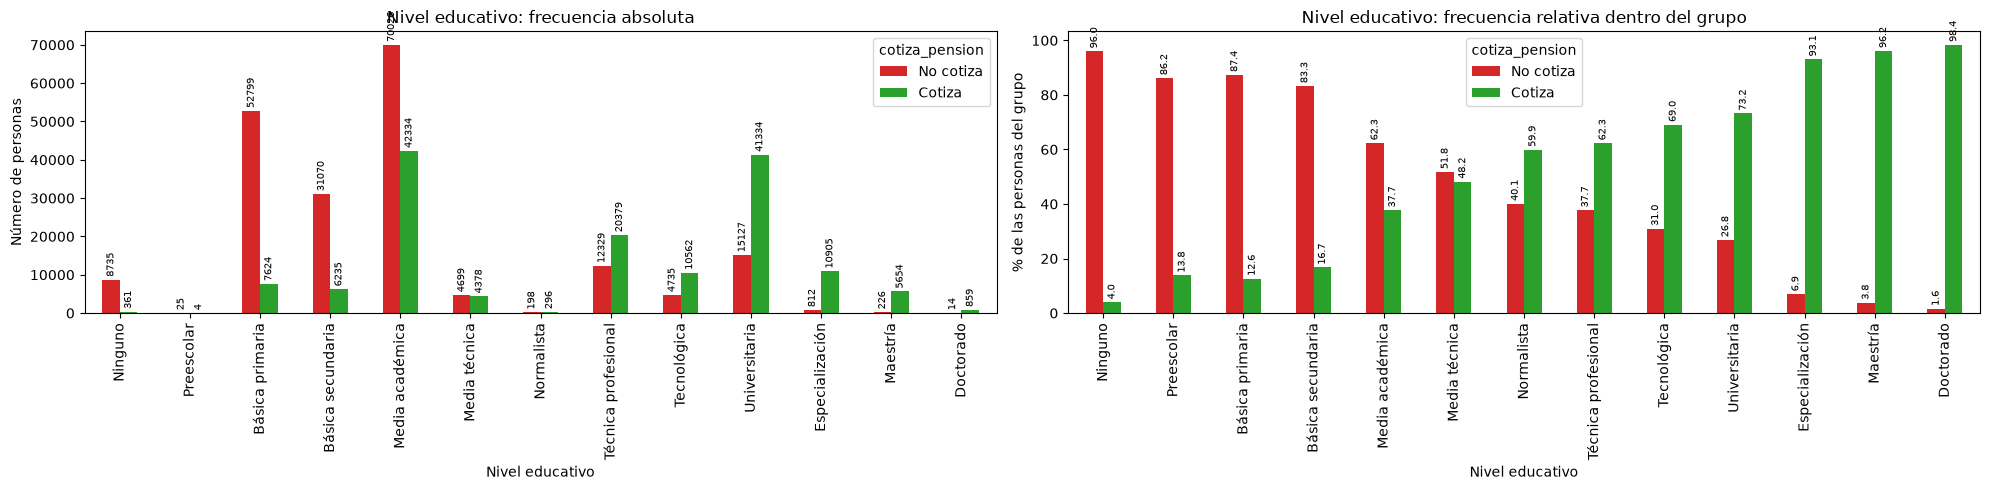

Frecuencia absoluta                % dentro del grupo  \
cotiza_pension                No cotiza Cotiza   Total          No cotiza   
nivel_educativo                                                             
Ninguno                            8735    361    9096               96.0   
Preescolar                           25      4      29               86.2   
Básica primaria                   52799   7624   60423               87.4   
Básica secundaria                 31070   6235   37305               83.3   
Media académica                   70026  42334  112360               62.3   
Media técnica                      4699   4378    9077               51.8   
Normalista                          198    296     494               40.1   
Técnica profesional               12329  20379   32708               37.7   
Tecnológica                        4735  10562   15297               31.0   
Universitaria                     15127  41334   56461               26.8   
Especialización                     812  10905   11717                6.9   
Maestría                            226   5654    5880                3.8   
Doctorado                            14    859     873                1.6   

                           % del total         
cotiza_pension      Cotiza   No cotiza Cotiza  
nivel_educativo                                
Ninguno                4.0         2.5    0.1  
Preescolar            13.8         0.0    0.0  
Básica primaria       12.6        15.0    2.2  
Básica secundaria     16.7         8.8    1.8  
Media académica       37.7        19.9   12.0  
Media técnica         48.2         1.3    1.2  
Normalista            59.9         0.1    0.1  
Técnica profesional   62.3         3.5    5.8  
Tecnológica           69.0         1.3    3.0  
Universitaria         73.2         4.3   11.8  
Especialización       93.1         0.2    3.1  
Maestría              96.2         0.1    1.6  
Doctorado             98.4         0.0    0.2

In [31]:
nivel_ord = pd.Series(pd.Categorical(df['nivel_educativo'], categories=orden_edu, ordered=True),
                      index=df.index, name='nivel_educativo')

graficar_frecuencias(nivel_ord, 'Nivel educativo', ancho=20, rotacion=90, tam_etiqueta=7, rot_etiqueta=90)
tabla_frecuencias(nivel_ord)

La educación es la variable que más separa. El grupo más grande es media académica (112.360 personas, 32 % del total), con 38 % de cotización, seguido de básica primaria (60.423) y universitaria (56.461). En términos absolutos, el mayor número de no cotizantes está en media académica (70.026) y básica primaria (52.799). En términos relativos, los niveles bajos casi no cotizan (4 % sin estudios, 13 % en primaria, 17 % en secundaria) y desde especialización cotiza más de 90 %. Los grupos pequeños (preescolar, normalista, doctorado) hay que leerlos con cuidado porque tienen pocos casos.

## 8. Conclusiones

1. **Casi 6 de cada 10 ocupados no cotiza a pensión** (57 % en la muestra; 56 % con factor de expansión); las clases no están muy desbalanceadas y la tasa es estable durante el año (42–44 % cada mes), lo que ayuda al split temporal.
2. **Las variables laborales pesan más que las personales:** posición ocupacional, tamaño de empresa y nivel educativo separan mucho más (de 4 % a más de 90 %) que el sexo (41 % frente a 45 %).
3. **El ingreso importa, pero no explica todo:** cerca de una cuarta parte de quienes ganan 1 SMMLV o más no cotiza, y ese grupo es el objetivo de política pública.
4. **La zona rural y el trabajo independiente o en empresas muy pequeñas concentran la baja cotización.**
5. **La edad tiene forma de montaña:** cotizan más de la mitad solo entre los 25 y 44 años; antes (35 %) y después (33 % a los 55–64 y 10 % desde los 65) cotizan mucho menos. Las mujeres cotizan más que los hombres hasta los 54 años, pero esa ventaja se invierte entre los 55 y 64 y desaparece desde los 65.
6. **Entre quienes no cotizan, tener contrato no cambia con la educación** (28–43 % en casi todos los niveles), mientras que ganar 1 SMMLV o más sí sube con el estudio.

**Avisos sobre los datos:**
- El factor de expansión no trae coma decimal en este archivo: ya viene con punto y como número.
- `parentesco_jefe` solo distingue jefe, pareja e hijo(a); los demás códigos se agruparon como "Otro" porque no se pudieron confirmar.
- `lugar_trabajo` y `estrato` se dejaron con su código original (en `estrato` hay valores 0 y 9 sin confirmar).
- En `tamano_empresa`, la separación de los códigos 9 (101 a 200) y 10 (201 o más) se dedujo del patrón de los datos, sin tabla oficial a la mano.
- En `posicion_ocupacional`, los códigos 7 (jornalero o peón) y 8 (otro) se dedujeron igual.

**Qué sigue:** split temporal (enero–septiembre entrenamiento, octubre–diciembre prueba), regresión logística y boosting, probando `tiene_contrato` con y sin ella.